In [333]:
import pandas as pd
import numpy as np
import random as rnd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier

submission = pd.read_csv("gender_submission.csv")
test = pd.read_csv("test.csv")
train = pd.read_csv("train.csv")

In [334]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [335]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [336]:
combine = [train, test] # 두 df를 결합

In [337]:
# 데이터 살펴보기

train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

범주형: survived, sex, embarked

순서형: pclass

연속형: age, fare

이산형: sibsp, parch

In [338]:
train.shape

(891, 12)

In [339]:
# 결측치 확인
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

In [340]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB

In [341]:
# 결측치 처리하기
# age, cabin, embarked 에 결측치 존재
# test 셋에는 fare 또한 결측치

# age -> 중앙값으로 대체
# cabin -> 결측치가 많아서 삭제
# embarked 최빈값 대체
# fare -> 중앙값 대체 

train['Age'] = train['Age'].fillna(train['Age'].median())
test['Age'] = test['Age'].fillna(test['Age'].median())

train.drop('Cabin', axis=1, inplace=True, errors='ignore')
test.drop('Cabin', axis=1, inplace=True, errors='ignore')

train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])
test['Fare'] = test['Fare'].fillna(test['Fare'].median())

In [342]:
train.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [343]:
test.isnull().sum()

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

결측치 처리 완료

In [344]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [345]:
test.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000
mean,1100.500000,2.265550,29.599282,0.447368,0.392344,35.576535
std,120.810458,0.841838,12.703770,0.896760,0.981429,55.850103
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,23.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,35.750000,1.000000,0.000000,31.471875
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


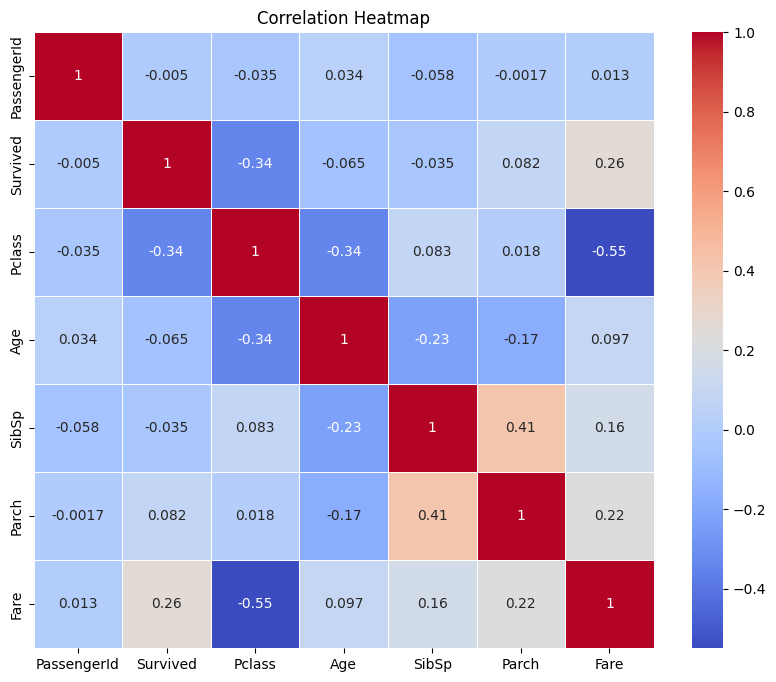

In [346]:
import seaborn as sns
import matplotlib.pyplot as plt

# 각 변수들간의 상관관계 시각화
corr_matrix = train.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [347]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [348]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,S


In [349]:
# 가정1: 객실 등급이 높으면 생존율이 올라갔을 것
train[['Pclass', 'Survived']]\
    .groupby(['Pclass'], as_index=False)\
    .mean()\
    .sort_values(by='Survived', ascending=False)

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


In [350]:
# 가정 2: 여성의 경우 생존율이 높았을 것
train[["Sex", "Survived"]]\
    .groupby(['Sex'], as_index=False)\
    .mean()\
    .sort_values(by='Survived', ascending=False)

,Sex,Survived
0,female,0.742038
1,male,0.188908


In [351]:
# 가정 3: 동승자수와 생존율은 관계가 있을 것
train[["SibSp", "Survived"]]\
    .groupby(['SibSp'], as_index=False)\
    .mean()\
    .sort_values(by='Survived', ascending=False)

,SibSp,Survived
1,1,0.535885
2,2,0.464286
0,0,0.345395
3,3,0.250000
4,4,0.166667
5,5,0.000000
6,8,0.000000


In [352]:
# 가정 4: 부모/자녀 수와 생존율은 관계가 있을 것
train[["Parch", "Survived"]]\
    .groupby(['Parch'], as_index=False)\
    .mean()\
    .sort_values(by='Survived', ascending=False)

,Parch,Survived
3,3,0.600000
1,1,0.550847
2,2,0.500000
0,0,0.343658
5,5,0.200000
4,4,0.000000
6,6,0.000000


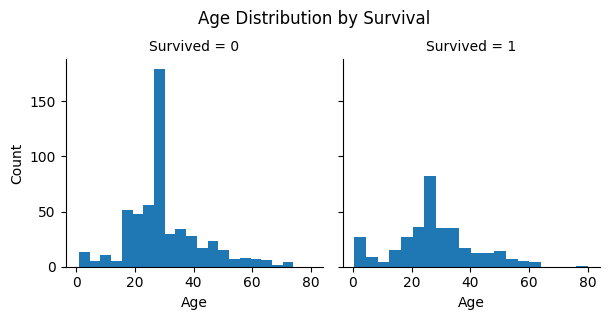

In [353]:
# 나이와 생존률에 대한 시각화

# Age vs Survived 시각화
g = sns.FacetGrid(train, col='Survived')
g.map(plt.hist, 'Age', bins=20)

g.set_axis_labels('Age', 'Count')
g.set_titles('Survived = {col_name}')
plt.suptitle('Age Distribution by Survival', y=1.05)
plt.show()

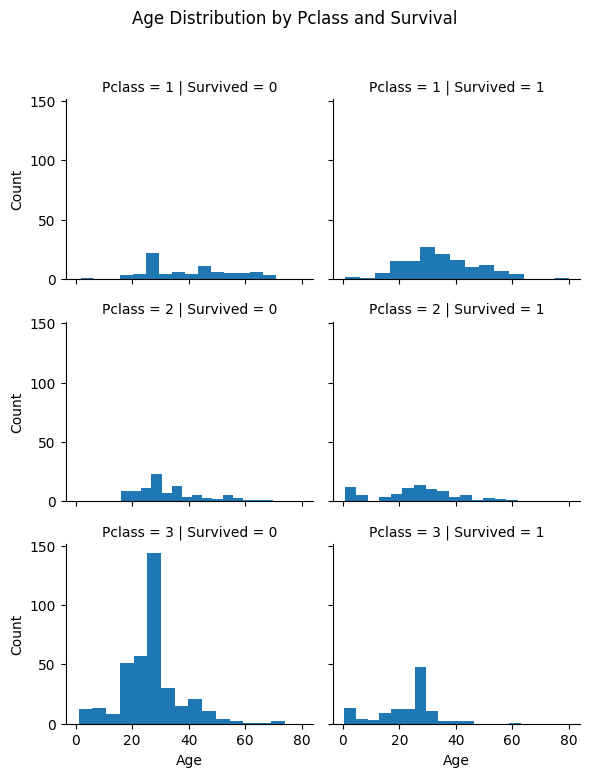

In [354]:
# Pclass, Age, 생존율을 동시에 비교
g = sns.FacetGrid(train, col='Survived', row='Pclass', height=2.5, aspect=1.2)
g.map(plt.hist, 'Age', bins=15)

g.set_axis_labels('Age', 'Count')
g.set_titles(row_template='Pclass = {row_name}', col_template='Survived = {col_name}')
plt.suptitle('Age Distribution by Pclass and Survival', y=1.03)
plt.tight_layout()
plt.show()

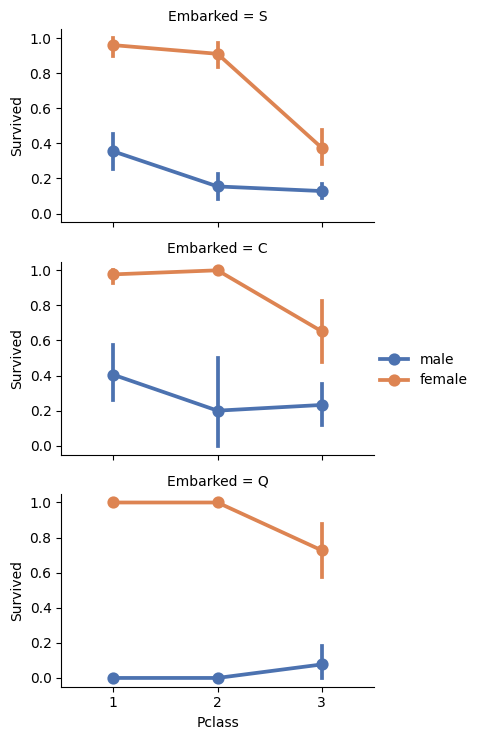

In [355]:
# 탑승항에 따른 생존율 분석
import seaborn as sns
import matplotlib.pyplot as plt


grid = sns.FacetGrid(train, row='Embarked', height=2.5, aspect=1.6)
grid.map(sns.pointplot, 'Pclass', 'Survived', 'Sex',
         palette='deep',
         order=[1, 2, 3],
         hue_order=['male', 'female'])
grid.add_legend()
plt.show()

In [356]:
# 피처 엔지니어링

# Ticket -> 제거
# PassengerId -> 단순 식별자 제거 ) (나중에 사용해야해서 나중에 따로 제거)
# Name -> 이 또한 단순 이름이므로 제거

# 새로운 변수 생성
# FamilySize -> SibSp + Parch + 1
# IsAlone -> FamilySize == 1
# Title -> 이름에서 호칭 추출
# AgeBand -> 연령을 구간으로 나눈 범주형 변수
# FareBand -> 요금을 구간으로 나눈 범주형 변수
import re

for df in [train, test]:
    df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

    # 흔하지 않은 호칭 통합
    df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col',
                                       'Don', 'Dr', 'Major', 'Rev', 'Sir',
                                       'Jonkheer', 'Dona'], 'Rare')
    df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')

    # 숫자 매핑
    title_mapping = {'Mr': 1, 'Miss': 2, 'Mrs': 3, 'Master': 4, 'Rare': 5}
    df['Title'] = df['Title'].map(title_mapping)
    df['Title'] = df['Title'].fillna(0)

train.drop(['Ticket', 'Name'], axis=1, inplace=True, errors='ignore')
test.drop(['Ticket', 'Name'], axis=1, inplace=True, errors='ignore')

# 파생변수 생성
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
test['FamilySize'] = test['SibSp'] + test['Parch'] + 1

train['IsAlone'] = (train['FamilySize'] == 1).astype(int)
test['IsAlone'] = (test['FamilySize'] == 1).astype(int)

train['AgeBand'] = pd.cut(train['Age'], 5, labels=False)
test['AgeBand'] = pd.cut(test['Age'], 5, labels=False)

train['FareBand'] = pd.qcut(train['Fare'], 4, labels=False)
test['FareBand'] = pd.qcut(test['Fare'], 4, labels=False)

train.drop(['SibSp', 'Parch', 'Age', 'Fare'], axis=1, inplace=True)
test.drop(['SibSp', 'Parch', 'Age', 'Fare'], axis=1, inplace=True)

In [357]:
# 범주형 데이터를 숫자형으로 변경

for df in [train, test]:
    df['Embarked'].fillna('S', inplace=True)

for df in [train, test]:
    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1}).astype(int)
    df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2}).astype(int)

In [358]:
print(train.dtypes)
print(test.dtypes)

PassengerId    int64
Survived       int64
Pclass         int64
Sex            int64
Embarked       int64
Title          int64
FamilySize     int64
IsAlone        int64
AgeBand        int64
FareBand       int64
dtype: object
PassengerId    int64
Pclass         int64
Sex            int64
Embarked       int64
Title          int64
FamilySize     int64
IsAlone        int64
AgeBand        int64
FareBand       int64
dtype: object

In [359]:
train.shape

(891, 10)

In [360]:
test.shape

(418, 9)

In [361]:
train[['Title', 'Survived']]\
    .groupby('Title', as_index=False)\
    .mean()\
    .sort_values(by='Survived', ascending=False)

# 3: Mrs
# 2: Miss
# 4: Master
# 5: Rare
# 1: Mr

,Title,Survived
2,3,0.793651
1,2,0.702703
3,4,0.575000
4,5,0.347826
0,1,0.156673


In [362]:
# 여러가지 모델을 사용하여 모델링
# 사용할 것
# 로지스틱 회귀
# K-최근접 이웃
# 나이브 베이즈
# 결정 트리
# 랜덤 포레스트

In [363]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Sex', 'Embarked', 'Title',
       'FamilySize', 'IsAlone', 'AgeBand', 'FareBand'],
      dtype='object')

In [367]:
# 그전에 학습데이터 준비
X_train = train.drop(["Survived", "PassengerId"], axis=1)
Y_train = train["Survived"]
X_test = test.drop(["PassengerId"], axis=1)

print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)

(891, 8)
(891,)
(418, 8)

In [368]:
# 로지스틱 회귀
logreg = LogisticRegression()
logreg.fit(X_train, Y_train)
Y_pred = logreg.predict(X_test)
acc_log = round(logreg.score(X_train, Y_train) * 100, 2)
acc_log

81.03

In [369]:
# KNN 최근접 이웃
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train, Y_train)
Y_pred = knn.predict(X_test)
acc_knn = round(knn.score(X_train, Y_train) * 100, 2)
acc_knn

85.19

In [370]:
# 나이브베이즈
gaussian = GaussianNB()
gaussian.fit(X_train, Y_train)
Y_pred = gaussian.predict(X_test)
acc_gaussian = round(gaussian.score(X_train, Y_train) * 100, 2)
acc_gaussian

80.13

In [371]:
# 결정 트리
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, Y_train)
Y_pred = decision_tree.predict(X_test)
acc_decision_tree = round(decision_tree.score(X_train, Y_train) * 100, 2)
acc_decision_tree

88.66

In [372]:
# 랜덤 포레스트
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train, Y_train)
Y_pred = random_forest.predict(X_test)
random_forest.score(X_train, Y_train)
acc_random_forest = round(random_forest.score(X_train, Y_train) * 100, 2)
acc_random_forest

88.66

# 모델 평가

랜덤 포레스트 = 결정 트리 > KNN > 로지스틱회귀 > 나이브베이즈

In [375]:
# 랜덤 포레스트로 모델 결정

submission = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "Survived": Y_pred
    })

submission.to_csv("submission.csv", index=False)

1. 사용한 모델 - 랜덤 포레스트
2. 주요 feature - 'Survived', 'Pclass', 'Sex', 'Embarked', 'Title',
'FamilySize', 'IsAlone', 'AgeBand', 'FareBand'
3. 전처리 방식 - 상관관계 분석 및 시각화를 이용 생존율과 관계가 높은 피처를 추출하고 유사한 피처를 통합함
4. 성능 요약 - score 함수를 이용하여 점수를 체크한 결과 랜덤 포레스트 및 결정트리의 점수가 가장 높았다.
5. 개선 방향 - 학습 데이터 셋이 적었기에 K-fold 와 같은 학습 기법을 사용하면 정확도를 더 높일 수 있을 것 같고, 다양한 모델을 조합하는 것도 고려해봄직 하다.